<div style="background:rgba(128,128,128,0.05);border:1px solid rgba(128,128,128,0.26);color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));border-radius:12px;padding:28px 30px;"><div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Qiskit Fall Fest Connecticut 2026 &nbsp;·&nbsp; qBraid challenge &nbsp;·&nbsp; Resource 1 of 3</span></div><div style="margin:0 0 14px 0;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:12px;letter-spacing:1px;color:rgba(128,128,128,0.98);white-space:nowrap;"><svg width="12" height="12" viewBox="0 0 24 24" fill="none" stroke="rgba(128,128,128,0.98)" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>about 35 minutes end to end</span></div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:38px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">A Qiskit refresher for <span style="color:#8B5CF6;">quantum optimization</span></div><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">On Friday you met Qiskit and ran your first circuit. Saturday's challenge asks for more: you turn a puzzle into a cost, then let a quantum circuit search for the cheapest answer. This notebook covers the Qiskit pieces that job needs, and nothing else.</p><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">Each section is a short experiment. You predict what happens, run the cell, and compare. The path:</p><ol style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:15px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;padding-left:22px;"><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Qubits, circuits and measurement.</b> <span style="color:rgba(128,128,128,0.98);">Build a circuit, run it, and read its counts in the right order.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Superposition and entanglement.</b> <span style="color:rgba(128,128,128,0.98);">Two gates that make the outcomes random and then tie them together.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Parameterized circuits.</b> <span style="color:rgba(128,128,128,0.98);">Circuits with a dial in them, the shape every variational algorithm uses.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Pauli operators and expectation values.</b> <span style="color:rgba(128,128,128,0.98);">How a quantum operator scores a bitstring like a classical function.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Rotations that encode a cost.</b> <span style="color:rgba(128,128,128,0.98);">The two gates that write a cost into the phases of a state.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Transpiling.</b> <span style="color:rgba(128,128,128,0.98);">How Qiskit rewrites your circuit into the gates a device runs.</span></li></ol><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">Every idea here comes back in the starter notebook, where the cost is the Instant Insanity puzzle.</p></div>

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Before you start</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

Run the two cells below: the first installs anything missing, and the second sets up plotting, with other helpers defined where they are first used.

In [1]:
import importlib.util
import subprocess
import sys

# install only what is missing; upgrading an already-imported package can break it
NEEDED = {"qiskit": "qiskit>=1.3,<3", "qiskit_aer": "qiskit-aer>=0.15",
          "qbraid": "qbraid[qiskit]>=0.12", "matplotlib": "matplotlib",
          "networkx": "networkx", "scipy": "scipy", "pylatexenc": "pylatexenc"}
missing = [spec for mod, spec in NEEDED.items()
           if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing],
                   check=True)
print("installed:", ", ".join(missing) or "nothing, everything was already here")

installed: nothing, everything was already here


In [2]:
import io

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
from IPython.display import Image, display

SEED = 7
GREY, VIOLET, TEAL, AMBER = "#8A8A8A", "#8B5CF6", "#0E9488", "#C2772A"
plt.rcParams.update({"figure.facecolor": "none", "axes.facecolor": "none",
                     "savefig.facecolor": "none", "savefig.edgecolor": "none",
                     "figure.dpi": 110, "axes.edgecolor": GREY,
                     "text.color": GREY, "axes.labelcolor": GREY,
                     "xtick.color": GREY, "ytick.color": GREY})


def show(fig):
    """Show a figure with a transparent background, whatever the page theme."""
    # sending the PNG ourselves stops the notebook painting a dark box behind it
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", transparent=True, bbox_inches="tight", dpi=110)
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 1 · Qubits, circuits and measurement</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How do you build a circuit and <span style="color:#8B5CF6;">read</span> its result?</div>

A **qubit** is the quantum version of a bit. Like a bit, it can be measured as 0 or 1. A **circuit** is a list of operations on qubits, read from left to right. The operations are called **gates**.

A qubit starts in the state $|0\rangle$. The `x` gate flips it to $|1\rangle$, the way a NOT gate flips a bit. A **measurement** reads the qubit and returns 0 or 1. One run of the circuit is a **shot**, and the tally of results over many shots is the **counts**.

The cell below builds a circuit with three qubits and flips only qubit 0. Before you run it, predict the result as a three-character string.

Qiskit draws circuits on a white background by default. The style below makes the drawing transparent, so it reads on a light or a dark page.

In [3]:
CIRCUIT = {"backgroundcolor": "#00000000", "linecolor": GREY,
           "textcolor": GREY, "subtextcolor": GREY, "gatetextcolor": "#FFFFFF",
           "displaycolor": {"h": (VIOLET, "#FFFFFF"), "x": (TEAL, "#FFFFFF"),
                            "ry": (VIOLET, "#FFFFFF"), "rx": (TEAL, "#FFFFFF"),
                            "rz": (AMBER, "#FFFFFF"), "rzz": (AMBER, "#FFFFFF"),
                            "cx": (TEAL, "#FFFFFF"), "cz": (AMBER, "#FFFFFF")}}

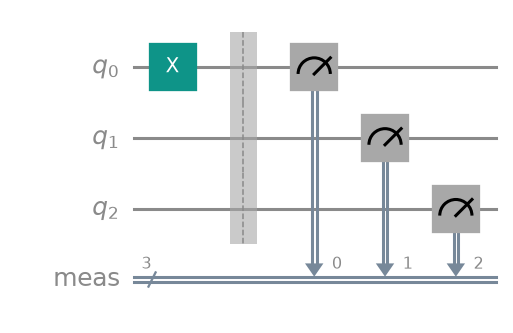

In [4]:
qc = QuantumCircuit(3)
qc.x(0)
qc.measure_all()
show(qc.draw("mpl", style=CIRCUIT))

The drawing shows the three qubit wires, `q_0` at the top. `measure_all` adds a **barrier**, the dashed line, and then one measurement per qubit. Each result lands in a classical bit on the bottom wire.

To run the circuit, use `AerSimulator`, a simulator that runs on this machine. `local_counts` runs a circuit and returns its counts, and `plot_counts` draws them as one bar per outcome.

{'001': 1000}


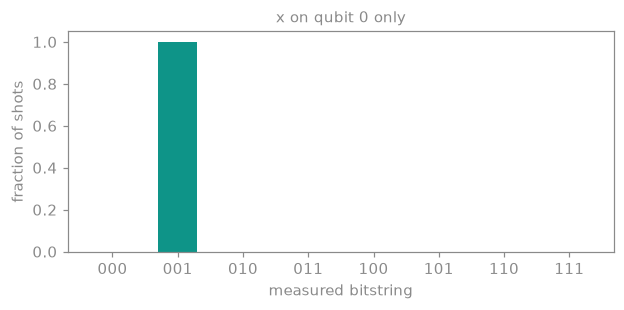

In [5]:
def local_counts(circuit, shots=1000):
    """Run a measured circuit on the local simulator and return its counts."""
    return AerSimulator(seed_simulator=SEED).run(circuit, shots=shots).result().get_counts()


def plot_counts(counts, title=""):
    shots = sum(counts.values())
    n = len(next(iter(counts)))
    labels = [format(i, f"0{n}b") for i in range(2 ** n)]
    fig, ax = plt.subplots(figsize=(1.6 + 0.6 * len(labels), 2.6))
    ax.bar(labels, [counts.get(k, 0) / shots for k in labels], color=TEAL, width=0.6)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("measured bitstring")
    ax.set_ylabel("fraction of shots")
    ax.set_title(title, fontsize=10)
    show(fig)


counts = local_counts(qc)
print(counts)
plot_counts(counts, "x on qubit 0 only")

Every shot returned `001`, not `100`. Qiskit writes qubit 0 as the **rightmost** character of each key, so a key reads from the last qubit down to qubit 0. This is called little-endian order.

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #8B5CF6;border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#8B5CF6;margin-bottom:7px;">Why the order matters</div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">In the challenge, each qubit stands for one decision about one cube. Read a key in the wrong order and you assign every decision to the wrong cube. Some devices report qubit 0 on the left instead, so always check the order before you decode.</div></div>

Check yourself: change `qc.x(0)` to `qc.x(2)` and predict the key before you run it.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 2 · Superposition and entanglement</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">What do the <span style="color:#8B5CF6;">H and CX</span> gates do to the outcomes?</div>

The **Hadamard** gate, `h`, puts a qubit in an equal **superposition** of 0 and 1. Measure it and you get each result half the time. The **controlled-NOT** gate, `cx`, flips a target qubit only when a control qubit is 1.

Apply `h` to qubit 0, then `cx` from qubit 0 to qubit 1. Predict the outcomes before you run the cell. `Statevector` computes the exact probabilities, and the simulator samples them.

exact: {np.str_('00'): 0.5, np.str_('11'): 0.5}
sampled: {'11': 511, '00': 489}


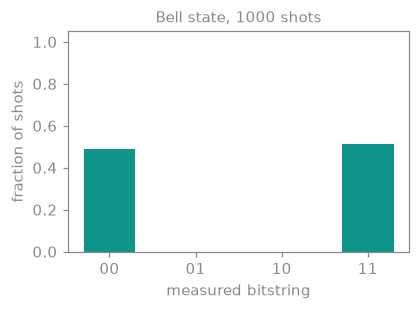

In [6]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
exact = Statevector(bell).probabilities_dict()
print("exact:", {bits: round(float(p), 3) for bits, p in exact.items()})

counts = local_counts(bell.measure_all(inplace=False))
print("sampled:", counts)
plot_counts(counts, "Bell state, 1000 shots")

Only `00` and `11` appear, each about half the time. The two qubits are random, but they always agree. This link between qubits is called **entanglement**, and this state is the **Bell state**.

The exact answer is 0.5 for each outcome. The sampled fractions sit near 0.5 but not on it, because 1000 shots is a finite sample. Expect a spread of about $1/\sqrt{1000} \approx 0.03$ whenever you read counts.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 3 · Parameterized circuits</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How do you put a <span style="color:#8B5CF6;">dial</span> into a circuit?</div>

A **parameter** is a gate angle you leave open and fill in later. The `ry` gate rotates a qubit by an angle $\theta$, so it moves the qubit smoothly from 0 towards 1. QAOA, the algorithm in the challenge, is a circuit with parameters that a classical optimizer tunes.

The cell below builds the circuit once with a `Parameter`, then fills in 21 angles with `assign_parameters`. Theory says the probability of measuring 1 is $\sin^2(\theta/2)$. Predict where it reaches 1.

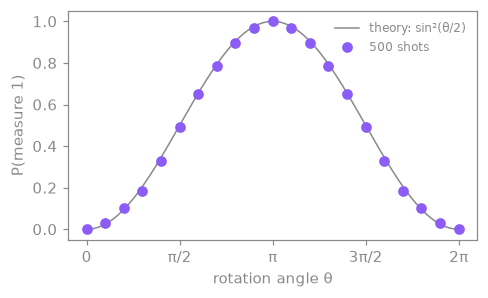

In [7]:
theta = Parameter("θ")
dial = QuantumCircuit(1)
dial.ry(theta, 0)
dial.measure_all()

angles = np.linspace(0, 2 * np.pi, 21)
measured = []
for angle in angles:
    counts = local_counts(dial.assign_parameters({theta: angle}), shots=500)
    measured.append(counts.get("1", 0) / 500)

fine = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(4.8, 2.7))
ax.plot(fine, np.sin(fine / 2) ** 2, color=GREY, lw=1, label="theory: sin²(θ/2)")
ax.plot(angles, measured, "o", color=VIOLET, label="500 shots")
ax.set_xticks(np.linspace(0, 2 * np.pi, 5), ["0", "π/2", "π", "3π/2", "2π"])
ax.set_xlabel("rotation angle θ")
ax.set_ylabel("P(measure 1)")
ax.legend(frameon=False, fontsize=8)
show(fig)

The dots follow the curve. The probability reaches 1 at $\theta = \pi$ and falls back to 0 at $\theta = 2\pi$. One circuit with a dial gave you a whole family of states.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 4 · Pauli operators and expectation values</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How can a quantum operator <span style="color:#8B5CF6;">score</span> a bitstring?</div>

A **Pauli operator** is a product of the matrices I, X, Y and Z, one per qubit. The `Z` operator gives $+1$ to the state $|0\rangle$ and $-1$ to $|1\rangle$. Qiskit stores these operators as `SparsePauliOp`.

The **expectation value** of an operator is its average score over many measurements of a state. `Statevector.expectation_value` computes it exactly. Predict the value of Z on $|0\rangle$, on $|1\rangle$, and on an equal superposition.

In [8]:
Z = SparsePauliOp("Z")
zero = Statevector.from_label("0")
one = Statevector.from_label("1")
plus = Statevector.from_label("+")
for name, state in [("|0>", zero), ("|1>", one), ("|+>", plus)]:
    print(name, round(state.expectation_value(Z).real, 6))

|0> 1.0
|1> -1.0
|+> 0.0


Z scores $|0\rangle$ as $+1$ and $|1\rangle$ as $-1$. The superposition scores 0, the average of the two.

Optimization problems use binary variables that are 0 or 1, not $+1$ or $-1$. The fix is one line: the operator $x = (I - Z)/2$ scores $|0\rangle$ as 0 and $|1\rangle$ as 1. It turns a qubit into a binary variable.

Now build a cost from two variables. Take $f(x_0, x_1) = x_0 + x_1 - 2x_0x_1$. It is 1 when the two bits differ and 0 when they agree. Replace each $x_i$ with its operator and let `SparsePauliOp` do the algebra.

<details style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #8B5CF6;border-radius:10px;padding:12px 18px;margin:16px 0;"><summary style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#8B5CF6;cursor:pointer;">The maths &nbsp;&middot;&nbsp; why the cost becomes one ZZ term<span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1.4px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-left:10px;">click to expand</span></summary>

Write $x_i = (1 - Z_i)/2$. Then $x_0 + x_1 = 1 - (Z_0 + Z_1)/2$.

The product is $x_0 x_1 = (1 - Z_0 - Z_1 + Z_0 Z_1)/4$, so $2x_0x_1 = (1 - Z_0 - Z_1 + Z_0Z_1)/2$.

Subtract, and the single-Z terms cancel:

$$f = \tfrac{1}{2}\left(I - Z_0 Z_1\right).$$

The cell below should print exactly this operator.

</details>

In [9]:
def x_var(i, n):
    """The binary-variable operator x_i = (I - Z_i) / 2 on n qubits."""
    return SparsePauliOp.from_sparse_list([("", [], 0.5), ("Z", [i], -0.5)], n)


x0, x1 = x_var(0, 2), x_var(1, 2)
cost = (x0 + x1 - 2 * (x0 @ x1)).simplify()
print(cost)

for bits in ["00", "01", "10", "11"]:
    state = Statevector.from_label(bits)
    b1, b0 = int(bits[0]), int(bits[1])  # rightmost character is qubit 0
    classical = b0 + b1 - 2 * b0 * b1
    print(bits, "operator:", round(state.expectation_value(cost).real, 6), "classical:", classical)

SparsePauliOp(['II', 'ZZ'],
              coeffs=[ 0.5+0.j, -0.5+0.j])
00 operator: 0.0 classical: 0
01 operator: 1.0 classical: 1
10 operator: 1.0 classical: 1
11 operator: 0.0 classical: 0


The operator prints as two terms, `II` and `ZZ`, each with weight $\pm 0.5$. On every bitstring the operator's expectation value equals the classical cost. An operator built only from I and Z is **diagonal**: it scores each bitstring without mixing them.

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #8B5CF6;border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#8B5CF6;margin-bottom:7px;">The bridge to the challenge</div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">A cost written this way is called a <b>cost Hamiltonian</b>. In the starter notebook you write the Instant Insanity rules as one, with the same <code>x_var</code> trick. The cheapest bitstring is the solved puzzle.</div></div>

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 5 · Rotations that encode a cost</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How does a circuit <span style="color:#8B5CF6;">write a cost</span> into a state?</div>

The `rz` gate applies $e^{-i\gamma Z/2}$. On a basis state it only multiplies the amplitude by a **phase**, a complex number of size 1. The probabilities do not change, so measuring right away shows nothing.

A phase does become visible when another gate makes amplitudes interfere. Put `rz` between two `h` gates. Theory says the probability of measuring 1 is $\sin^2(\gamma/2)$. Predict the value at $\gamma = \pi/2$.

<details style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #8B5CF6;border-radius:10px;padding:12px 18px;margin:16px 0;"><summary style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#8B5CF6;cursor:pointer;">The maths &nbsp;&middot;&nbsp; the rz and rzz matrices<span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1.4px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-left:10px;">click to expand</span></summary>

On one qubit, $R_Z(\gamma) = \mathrm{diag}(e^{-i\gamma/2}, e^{i\gamma/2})$. It gives the two basis states opposite phases.

On two qubits, $R_{ZZ}(\gamma) = e^{-i\gamma Z_0Z_1/2}$ is also diagonal. It gives phase $e^{-i\gamma/2}$ to `00` and `11`, where $Z_0Z_1 = +1$, and $e^{i\gamma/2}$ to `01` and `10`, where $Z_0Z_1 = -1$.

</details>

In [10]:
for gamma in [0, np.pi / 2, np.pi]:
    probe = QuantumCircuit(1)
    probe.h(0)
    probe.rz(gamma, 0)
    probe.h(0)
    p1 = Statevector(probe).probabilities()[1]
    print(f"gamma = {gamma:.3f}  P(1) = {p1:.3f}  theory = {np.sin(gamma / 2) ** 2:.3f}")

gamma = 0.000  P(1) = 0.000  theory = 0.000
gamma = 1.571  P(1) = 0.500  theory = 0.500
gamma = 3.142  P(1) = 1.000  theory = 1.000


At $\gamma = \pi/2$ the probability is 0.5, and at $\gamma = \pi$ the phase alone sends every shot to 1.

The `rzz` gate does the same for a pair of qubits. It applies $e^{-i\gamma Z_0Z_1/2}$, which phases each bitstring by whether its two bits agree. That is exactly the ZZ term of the cost from Section 4.

So `rzz` can apply the whole cost as a phase. Up to a global phase, $e^{-i\gamma f}$ with $f = (I - Z_0Z_1)/2$ equals `rzz` with angle $-\gamma$. The cell checks this claim as matrices, then shows the phase each bitstring receives.

In [11]:
gamma = 0.8
layer = QuantumCircuit(2)
layer.rzz(-gamma, 0, 1)

f_matrix = cost.to_matrix()
target = np.diag(np.exp(-1j * gamma * np.diag(f_matrix)))
print("rzz(-gamma) equals exp(-i gamma f) up to a global phase:",
      Operator(layer).equiv(Operator(target)))

state = Statevector.from_label("++").evolve(layer)
for bits, amp in zip(["00", "01", "10", "11"], state.data):
    print(bits, "cost", int(np.diag(f_matrix).real[int(bits, 2)]),
          " phase", round(float(np.angle(amp)), 3))

rzz(-gamma) equals exp(-i gamma f) up to a global phase: True
00 cost 0  phase 0.4
01 cost 1  phase -0.4
10 cost 1  phase -0.4
11 cost 0  phase 0.4


Bitstrings with cost 0 share one phase, and bitstrings with cost 1 share another. The difference is $\gamma$, set by the cost. This is the **cost layer** of QAOA. A second layer of `rx` gates, the **mixer**, then makes those phases interfere, so cheap bitstrings grow more likely. Resource 3 builds both layers.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 6 · Transpiling</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How does Qiskit prepare a circuit for a <span style="color:#8B5CF6;">device</span>?</div>

A real device runs only a short list of native gates, its **basis gates**. **Transpiling** rewrites your circuit into those gates. It also simplifies the result where it can.

The cell builds a small circuit with `h`, `rzz` and `ry`, then transpiles it to the basis `rz`, `sx`, `x` and `cx`. The **depth** is the number of gate layers in the longest path through the circuit. Predict whether the depth goes up or down.

before: {'h': 3, 'ry': 3, 'rzz': 2} depth 4
after:  {'rz': 14, 'sx': 9, 'cx': 4} depth 13


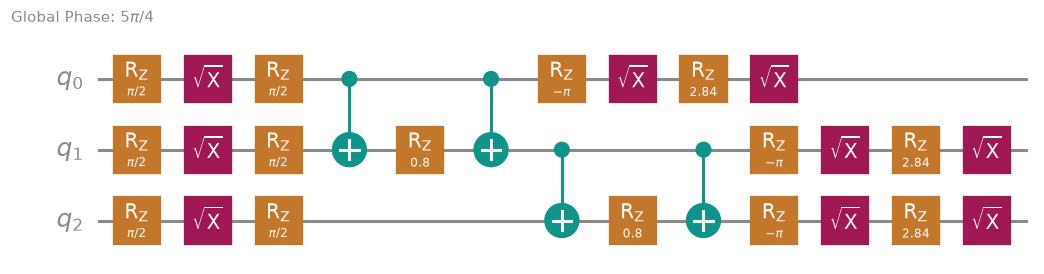

In [12]:
demo = QuantumCircuit(3)
demo.h([0, 1, 2])
demo.rzz(0.8, 0, 1)
demo.rzz(0.8, 1, 2)
demo.ry(0.3, [0, 1, 2])

compiled = transpile(demo, basis_gates=["rz", "sx", "x", "cx"],
                     optimization_level=1, seed_transpiler=SEED)
print("before:", dict(demo.count_ops()), "depth", demo.depth())
print("after: ", dict(compiled.count_ops()), "depth", compiled.depth())
show(compiled.draw("mpl", style=CIRCUIT, fold=-1))

Each `rzz` became two `cx` gates around an `rz`. The `h` and `ry` gates became `rz` and `sx` sequences, so the depth grew from 4 to 13. Depth matters because every layer adds noise on real hardware. In the challenge, a shallower circuit for the same answer is a better circuit.

The qBraid SDK, in the next notebook, accepts Qiskit circuits and converts them for each device. Transpiling first keeps that conversion simple.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

What you used in this refresher:

- **Counts** are keyed with qubit 0 on the right, so check the order before you decode.
- **Superposition** and **entanglement** come from `h` and `cx`.
- A **parameter** turns one circuit into a family of states.
- The operator $x = (I - Z)/2$ turns a qubit into a **binary variable**, so a classical cost becomes a **cost Hamiltonian**.
- `rz` and `rzz` write that cost into **phases**, which is the QAOA cost layer.
- **Transpiling** rewrites a circuit into a device's basis gates, and **depth** measures its cost.

<div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:12px;color:#8B5CF6;line-height:1.6;">END OF RESOURCE 1</div>

Next, `02_qbraid_sdk.ipynb` sends circuits like these to AWS SV1 through the qBraid platform.